Starting simulation at t=0. s for a duration of 10. ks
85.4469 s (0%) simulated in 10s, estimated 19m 20s remaining.
155.0453 s (1%) simulated in 20s, estimated 21m 10s remaining.
222.5776 s (2%) simulated in 30s, estimated 21m 58s remaining.
306.7637 s (3%) simulated in 40s, estimated 21m 4s remaining.
0.3750217 ks (3%) simulated in 50s, estimated 21m 23s remaining.
0.4442887 ks (4%) simulated in 1m 0s, estimated 21m 30s remaining.
0.5326003 ks (5%) simulated in 1m 10s, estimated 20m 44s remaining.
0.6033426 ks (6%) simulated in 1m 20s, estimated 20m 46s remaining.
0.674169 ks (6%) simulated in 1m 30s, estimated 20m 45s remaining.
0.7634283 ks (7%) simulated in 1m 40s, estimated 20m 10s remaining.
0.8348937 ks (8%) simulated in 1m 50s, estimated 20m 8s remaining.
0.9056302 ks (9%) simulated in 2m 0s, estimated 20m 5s remaining.
0.9939427 ks (9%) simulated in 2m 10s, estimated 19m 38s remaining.
1.0656462 ks (10%) simulated in 2m 20s, estimated 19m 34s remaining.
1.1365293 ks (11%) sim

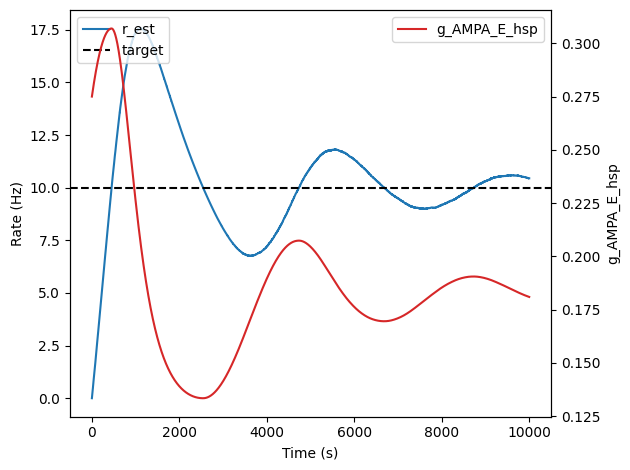

In [10]:
from brian2 import *

start_scope()
defaultclock.dt = 0.1*ms

V_L = -70*mV
V_thr = -50*mV
V_reset = -55*mV
V_E = 0*mV

C_m_E = 0.5*nF
g_m_E = 10*nS
tau_AMPA = 8*ms

tau_HSP = 2000*second
target_rate = 10*Hz

tau_ins_AMPA_E = 5000*second
tau_int_AMPA_E = 500*second

eqs_E = '''
dv/dt = (-g_m_E*(v - V_L) - I_syn)/C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext : amp

I_AMPA_ext = g_AMPA_ext_E * g_AMPA_E_hsp * (v - V_E) * s_AMPA_ext : amp

ds_AMPA_ext/dt = -s_AMPA_ext/tau_AMPA : 1

dx_spike/dt = -x_spike/tau_HSP : 1
r_est = x_spike/tau_HSP : Hz

dg_AMPA_E_hsp/dt = ((1 - g_AMPA_E_hsp) *
                    clip((target_rate - r_est)/target_rate, 0, 1)
                    / tau_ins_AMPA_E
                    - (g_AMPA_E_hsp - 0.1) *
                    clip((r_est - target_rate)/target_rate, 0, 1)
                    / tau_int_AMPA_E) : 1
'''

P = NeuronGroup(1, eqs_E,
                threshold='v > V_thr',
                reset='v = V_reset; x_spike += 1.',
                refractory=2*ms,
                method='euler')

P.v = V_L
P.g_AMPA_E_hsp = 0.275  

g_AMPA_ext_E = 6.5*nS

rate_in = 20*Hz  
inp = PoissonGroup(20, rates=rate_in)

S = Synapses(inp, P, model='w:1', on_pre='s_AMPA_ext += w')
S.connect()
S.w = 1.0

# Monitors
mon = StateMonitor(P, ['v', 'r_est', 'g_AMPA_E_hsp'], record=True, dt=100*ms)
sp = SpikeMonitor(P)

# Run long enough that HSP can act
run(10000*second, report='text')

# Quick plot
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots()
ax1.plot(mon.t/second, mon.r_est[0]/Hz, label='r_est')
ax1.axhline(target_rate/Hz, color='k', linestyle='--', label='target')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Rate (Hz)')
ax1.legend(loc='upper left')

ax2 = ax1.twinx()
ax2.plot(mon.t/second, mon.g_AMPA_E_hsp[0], color='tab:red', label='g_AMPA_E_hsp')
ax2.set_ylabel('g_AMPA_E_hsp')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()
